# Data pre-processing and correlation analysis

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import time
import zipfile
from pathlib import Path

try:
    import requests
except ImportError as exc:
    raise ImportError(
        "The notebook needs the 'requests' package for robust downloads. "
        "Install it with: conda install requests  (or pip install requests)"
    ) from exc

# Add the 'src' directory to the system path
# Search both the current working directory and its parent so the notebook is
# robust when opened from the project root or from a notebooks/ subdirectory.
_candidate_src_dirs = [
    Path.cwd() / "src",
    Path.cwd().parent / "src",
]
for _src in _candidate_src_dirs:
    if _src.exists():
        sys.path.insert(0, str(_src.resolve()))
        break

# Now you can import the module
try:
    import standardised_pipeline_utils
except ImportError as exc:
    raise ImportError(
        "Could not import standardised_pipeline_utils. Keep the project's 'src' "
        "folder next to the notebook/project root, or add that folder to PYTHONPATH."
    ) from exc

from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load

# Ensure the 'data' directory exists
data_dir = Path.cwd() / "data"
data_dir.mkdir(parents=True, exist_ok=True)

mods = {"pandas": pd, "numpy": np, "matplotlib": sys.modules.get("matplotlib"),
        "scikit-learn": sys.modules.get("sklearn"), "joblib": sys.modules.get("joblib"),
        "standardised_pipeline_utils": sys.modules.get("standardised_pipeline_utils")}
print(f"{'python':<28} {sys.version.split()[0]}")
for n, m in mods.items():
    print(f"{n:<28} {getattr(m, '__version__', '(no __version__)') if m else 'not loaded'}")


# Paper-ready figure output
FIGURE_DIR = Path("figures_pdf")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.size": 20,
    "axes.titlesize": 24,
    "axes.labelsize": 22,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 17,
    "figure.titlesize": 26,
    "axes.linewidth": 1.5,
    "lines.linewidth": 3.0,
})

def save_pdf(fig, stem):
    """Save a paper-ready vector PDF without clipping labels."""
    fig.savefig(
        FIGURE_DIR / f"{stem}.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.12,
    )


def _download_file(url, destination, retries=5, chunk_size=1024 * 1024,
                   validate_xlsx=False):
    """Download a file robustly, retrying interrupted/incomplete transfers."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    tmp = destination.with_suffix(destination.suffix + ".part")

    def _valid_existing(path):
        if not path.exists() or path.stat().st_size == 0:
            return False
        return zipfile.is_zipfile(path) if validate_xlsx else True

    if _valid_existing(destination):
        print(f"Using local file: {destination}")
        return destination

    if destination.exists():
        print(f"Removing incomplete/corrupt file: {destination}")
        destination.unlink()

    for attempt in range(1, retries + 1):
        try:
            if tmp.exists():
                tmp.unlink()
            print(f"Downloading {destination.name} (attempt {attempt}/{retries}) ...")
            with requests.get(
                url,
                stream=True,
                timeout=(30, 300),
                headers={"User-Agent": "Mozilla/5.0", "Accept": "*/*"},
                allow_redirects=True,
            ) as response:
                response.raise_for_status()
                expected = int(response.headers.get("content-length", 0) or 0)
                with tmp.open("wb") as handle:
                    for chunk in response.iter_content(chunk_size=chunk_size):
                        if chunk:
                            handle.write(chunk)

            actual = tmp.stat().st_size
            if expected and actual != expected:
                raise IOError(
                    f"Incomplete download: received {actual:,} bytes, "
                    f"expected {expected:,} bytes."
                )
            if validate_xlsx and not zipfile.is_zipfile(tmp):
                raise IOError("Downloaded file is not a valid .xlsx workbook.")
            if actual == 0:
                raise IOError("Downloaded file is empty.")

            tmp.replace(destination)
            print(f"Download complete: {destination} ({actual / 1024**2:.1f} MB)")
            return destination
        except Exception as exc:
            if tmp.exists():
                tmp.unlink()
            if attempt == retries:
                raise RuntimeError(
                    f"Could not download {url} after {retries} attempts. "
                    f"Place the file manually at {destination}."
                ) from exc
            wait = 5 * attempt
            print(f"Attempt {attempt} failed: {exc}. Retrying in {wait} s ...")
            time.sleep(wait)


def _load_csv_local_or_download(local_path, url):
    """Load a CSV locally; if absent, download it once and then read locally."""
    local_path = Path(local_path)
    if not local_path.exists() or local_path.stat().st_size == 0:
        _download_file(url, local_path)
    return pd.read_csv(local_path)


def _load_proteomics_table():
    """Load the CCLE proteomics table without reading a large XLSX directly over HTTP."""
    local_csv = data_dir / "Table_S2_Protein_Quant_Normalized.csv"
    local_xlsx = data_dir / "Table_S2_Protein_Quant_Normalized.xlsx"
    url = "https://gygi.hms.harvard.edu/data/ccle/Table_S2_Protein_Quant_Normalized.xlsx"

    if local_csv.exists() and local_csv.stat().st_size > 0:
        print(f"Using local proteomics CSV: {local_csv}")
        return pd.read_csv(local_csv)

    _download_file(url, local_xlsx, validate_xlsx=True)
    return pd.read_excel(local_xlsx, sheet_name=1, engine="openpyxl")


def _harmonize_transcriptomics(raw, sample_info):
    """
    Return transcriptomics as samples x genes, regardless of whether the input
    CSV arrived as samples x genes or genes x samples and regardless of whether
    its identifier column was already used as the index.
    """
    df = raw.copy()

    # Recover an identifier column when pandas loaded it as an ordinary column.
    if "Unnamed: 0" in df.columns:
        df = df.set_index("Unnamed: 0")
    elif isinstance(df.index, pd.RangeIndex) and len(df.columns):
        first = df.columns[0]
        first_values = df[first]
        if (not pd.api.types.is_numeric_dtype(first_values)
                and first_values.notna().all()
                and first_values.astype(str).is_unique):
            df = df.set_index(first)

    df.index = pd.Index(df.index).astype(str).str.strip()
    df.columns = pd.Index(df.columns).astype(str).str.strip()

    # Use the annotation table to determine which axis contains cell lines.
    sample_names = set()
    depmap_to_ccle = {}
    if isinstance(sample_info, pd.DataFrame):
        if "CCLE_Name" in sample_info.columns:
            sample_names.update(sample_info["CCLE_Name"].dropna().astype(str).str.strip())
        if "DepMap_ID" in sample_info.columns:
            depmap_ids = sample_info["DepMap_ID"].dropna().astype(str).str.strip()
            sample_names.update(depmap_ids)
        if {"DepMap_ID", "CCLE_Name"}.issubset(sample_info.columns):
            pairs = sample_info[["DepMap_ID", "CCLE_Name"]].dropna().astype(str)
            depmap_to_ccle = dict(zip(pairs["DepMap_ID"].str.strip(),
                                      pairs["CCLE_Name"].str.strip()))

    row_matches = sum(label in sample_names for label in df.index)
    col_matches = sum(label in sample_names for label in df.columns)

    # Extra fallback heuristic for DepMap identifiers.
    row_ach = sum(label.startswith("ACH-") for label in df.index)
    col_ach = sum(label.startswith("ACH-") for label in df.columns)

    if col_matches > row_matches or (col_matches == row_matches == 0 and col_ach > row_ach):
        print("Transcriptomics detected as genes x samples; transposing to samples x genes.")
        df = df.T
    else:
        print("Transcriptomics detected as samples x genes; keeping current orientation.")

    df.index = pd.Index(df.index).astype(str).str.strip()
    df.columns = pd.Index(df.columns).astype(str).str.strip()

    # Convert DepMap IDs to CCLE names only when the row labels are DepMap IDs.
    if depmap_to_ccle:
        df = df.rename(index=depmap_to_ccle)

    # Strip Entrez IDs such as "TSPAN6 (7105)" while leaving plain symbols unchanged.
    df.columns = [str(x).split(" ")[0] for x in df.columns]

    # If cleaning creates duplicate gene labels, keep them here; the next
    # processing step intentionally collapses same-gene rows after transpose.
    if df.index.duplicated().any():
        # Duplicate sample rows are not expected. Average only as a robust fallback.
        ndup = int(df.index.duplicated(keep=False).sum())
        print(f"Warning: {ndup} duplicate sample rows detected; averaging duplicates.")
        df = df.groupby(level=0, sort=False).mean(numeric_only=True)

    print("Harmonized transcriptomics shape (samples x genes):", df.shape)
    print("Sample examples:", df.index[:5].tolist())
    print("Gene examples:", df.columns[:5].tolist())
    return df


python                       3.11.5
pandas                       2.3.2
numpy                        1.26.4
matplotlib                   3.10.8
scikit-learn                 1.7.2
joblib                       1.2.0
standardised_pipeline_utils  (no __version__)


#### Datasets Used:

Transcriptomics (CCLE / DepMap 20Q4)
Bulk RNA-seq for hundreds of cancer cell lines, processed through a standardized DepMap pipeline and released as TPM (and commonly log2(TPM+1)) matrices. Harmonized metadata and stable sample IDs make it easy to line up with other CCLE/DepMap modalities for integrative analysis.
<a href=https://www.nature.com/articles/s41586-019-1186-3>Next-generation characterization of the Cancer Cell Line Encyclopedia</a>

Proteomics (Gygi Lab CCLE)
Tandem mass-tag (TMT) quantitative proteomics profiling of CCLE lines, providing deep, relative protein abundance across thousands of proteins. Uniform sample prep and processing yield a high-quality matrix that pairs directly with CCLE transcriptomics for mRNA–protein comparisons. <a href=https://gygi.hms.harvard.edu/publications/ccle.html>Gygi Lab CCLE Proteomics</a>

In [2]:
# transcript level data/ transcript expression data/ transcript quantification data
# 1376 samples (cell lines) * 52003 genes
# both are log_2(x+1) transformed
# Robust behavior: use the local copy when available; otherwise download it once.
transcriptomics = _load_csv_local_or_download(
    data_dir / "CCLE_expression_full.csv",
    "https://figshare.com/ndownloader/files/25797014",
)
transcriptomics.head()


,Unnamed: 0,TSPAN6 (ENSG00000000003),TNMD (ENSG00000000005),DPM1 (ENSG00000000419),SCYL3 (ENSG00000000457),C1orf112 (ENSG00000000460),FGR (ENSG00000000938),CFH (ENSG00000000971),FUCA2 (ENSG00000001036),GCLC (ENSG00000001084),...,ERCC-00157,ERCC-00158,ERCC-00160,ERCC-00162,ERCC-00163,ERCC-00164,ERCC-00165,ERCC-00168,ERCC-00170,ERCC-00171
0,ACH-001113,4.990501,0.000000,7.273702,2.765535,4.480265,0.028569,1.269033,3.058316,6.483171,...,0.000000,0.000000,0.150560,2.599318,0.887525,0.000000,0.650765,0.042644,0.344828,7.053872
1,ACH-001289,5.209843,0.545968,7.070604,2.538538,3.510962,0.000000,0.176323,3.836934,4.200850,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,ACH-001339,3.779260,0.000000,7.346425,2.339137,4.254745,0.056584,1.339137,6.724241,3.671293,...,0.286881,0.028569,0.505891,3.744161,1.669027,0.000000,1.454176,0.056584,0.757023,8.763445
3,ACH-001538,5.726831,0.000000,7.086189,2.543496,3.102658,0.000000,5.914565,6.099716,4.475733,...,0.201634,0.070389,0.516015,3.941106,1.807355,0.028569,1.560715,0.070389,0.941106,9.021757
4,ACH-000242,7.465648,0.000000,6.435462,2.414136,3.864929,0.831877,7.198003,5.452530,7.112492,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [3]:
#in case link doesn't work directly , you can download the file from figshare or dedicated drive and load it locally
# This is now a safe fallback cell: running the whole notebook does not overwrite
# an already loaded object, and running this cell alone uses the local file if present.
if "transcriptomics" not in globals():
    local_transcriptomics = data_dir / "CCLE_expression_full.csv"
    if not local_transcriptomics.exists():
        raise FileNotFoundError(
            f"Local transcriptomics file not found: {local_transcriptomics}"
        )
    transcriptomics = pd.read_csv(local_transcriptomics)
else:
    print("Transcriptomics already loaded; keeping the existing object.")


Transcriptomics already loaded; keeping the existing object.


In [4]:
# Protein level data/ protein expression data/ protein quantification data
# 12755 proteins * 16386 columns (annotation, quantification and NA columns)
# Download first and read locally, so an interrupted HTTP transfer cannot cause
# pandas/http.client IncompleteRead while parsing the workbook.
proteomics = _load_proteomics_table()
proteomics.head()


Using local file: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\01. pre-processing\data\Table_S2_Protein_Quant_Normalized.xlsx


,Protein_Id,Gene_Symbol,Description,Group_ID,Uniprot,Uniprot_Acc,TenPx01_Peptides,TenPx02_Peptides,TenPx03_Peptides,TenPx04_Peptides,...,Column15949,Column15950,Column15951,Column15952,Column15953,Column15954,Column15955,Column15956,Column15957,Column15958
0,sp|P55011|S12A2_HUMAN,SLC12A2,S12A2_HUMAN Solute carrier family 12 member 2,0,S12A2_HUMAN,P55011,41,16,23,59,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,sp|P35453|HXD13_HUMAN,HOXD13,HXD13_HUMAN Homeobox protein Hox-D13,1,HXD13_HUMAN,P35453,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,sp|O60341|KDM1A_HUMAN,KDM1A,KDM1A_HUMAN Lysine-specific histone demethylas...,2,KDM1A_HUMAN,O60341,25,35,37,40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,sp|O00570|SOX1_HUMAN,SOX1,SOX1_HUMAN Transcription factor SOX-1,4,SOX1_HUMAN,O00570,0,0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,sp|P48431|SOX2_HUMAN,SOX2,SOX2_HUMAN Transcription factor SOX-2,4,SOX2_HUMAN,P48431,1,0,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
#in case link doesn't work directly , you can download the file online or dedicated drive and load it locally
# Safe optional fallback: it does not overwrite a table that was already loaded.
if "proteomics" not in globals():
    local_proteomics_csv = data_dir / "Table_S2_Protein_Quant_Normalized.csv"
    if not local_proteomics_csv.exists():
        raise FileNotFoundError(
            f"Local proteomics CSV not found: {local_proteomics_csv}"
        )
    proteomics = pd.read_csv(local_proteomics_csv)
else:
    print("Proteomics already loaded; keeping the existing object.")


Proteomics already loaded; keeping the existing object.


In [6]:
# Annotation file for the cell lines (one sample is one cell line)
# Use the local copy when available; otherwise download it once.
sample_info = _load_csv_local_or_download(
    data_dir / "sample_info.csv",
    "https://figshare.com/ndownloader/files/25494443",
)
sample_info.head()


,DepMap_ID,cell_line_name,stripped_cell_line_name,CCLE_Name,alias,COSMICID,sex,source,Achilles_n_replicates,cell_line_NNMD,...,primary_or_metastasis,primary_disease,Subtype,age,Sanger_Model_ID,depmap_public_comments,lineage,lineage_subtype,lineage_sub_subtype,lineage_molecular_subtype
0,ACH-000001,NIH:OVCAR-3,NIHOVCAR3,NIHOVCAR3_OVARY,OVCAR3,905933.0,Female,ATCC,NaN,NaN,...,Metastasis,Ovarian Cancer,"Adenocarcinoma, high grade serous",60.0,SIDM00105,NaN,ovary,ovary_adenocarcinoma,high_grade_serous,NaN
1,ACH-000002,HL-60,HL60,HL60_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NaN,905938.0,Female,ATCC,NaN,NaN,...,Primary,Leukemia,"Acute Myelogenous Leukemia (AML), M3 (Promyelo...",35.0,SIDM00829,NaN,blood,AML,M3,NaN
2,ACH-000003,CACO2,CACO2,CACO2_LARGE_INTESTINE,"CACO2, CaCo-2",NaN,Male,ATCC,NaN,NaN,...,NaN,Colon/Colorectal Cancer,Adenocarcinoma,NaN,SIDM00891,NaN,colorectal,colorectal_adenocarcinoma,NaN,NaN
3,ACH-000004,HEL,HEL,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NaN,907053.0,Male,DSMZ,2.0,-3.079202,...,NaN,Leukemia,"Acute Myelogenous Leukemia (AML), M6 (Erythrol...",30.0,SIDM00594,NaN,blood,AML,M6,NaN
4,ACH-000005,HEL 92.1.7,HEL9217,HEL9217_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NaN,NaN,Male,ATCC,2.0,-2.404409,...,NaN,Leukemia,"Acute Myelogenous Leukemia (AML), M6 (Erythrol...",30.0,SIDM00593,NaN,blood,AML,M6,NaN


In [7]:
#in case link doesn't work directly , you can download the file from figshare or dedicated drive and load it locally
# Safe optional fallback: running all cells will not overwrite sample_info.
if "sample_info" not in globals():
    local_sample_info = data_dir / "sample_info.csv"
    if not local_sample_info.exists():
        raise FileNotFoundError(f"Local sample-info file not found: {local_sample_info}")
    sample_info = pd.read_csv(local_sample_info)
else:
    print("sample_info already loaded; keeping the existing object.")


sample_info already loaded; keeping the existing object.


### Transcriptomics: Upadhya processing and saving

In [8]:
# Harmonize rownames and colnames
# The source CSV exists in more than one orientation in practice.  This helper
# detects whether samples are on rows or columns and returns samples x genes.
# It also handles the case where "Unnamed: 0" is already the DataFrame index.
transcriptomics = _harmonize_transcriptomics(transcriptomics, sample_info)
transcriptomics.head()


Transcriptomics detected as samples x genes; keeping current orientation.
Harmonized transcriptomics shape (samples x genes): (1376, 52003)
Sample examples: ['LC1SQSF_LUNG', 'COGAR359_SOFT_TISSUE', 'COLO794_SKIN', 'KKU213_BILIARY_TRACT', 'RT4_URINARY_TRACT']
Gene examples: ['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112']


,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2,GCLC,NFYA,...,ERCC-00157,ERCC-00158,ERCC-00160,ERCC-00162,ERCC-00163,ERCC-00164,ERCC-00165,ERCC-00168,ERCC-00170,ERCC-00171
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
LC1SQSF_LUNG,4.990501,0.000000,7.273702,2.765535,4.480265,0.028569,1.269033,3.058316,6.483171,5.053980,...,0.000000,0.000000,0.150560,2.599318,0.887525,0.000000,0.650765,0.042644,0.344828,7.053872
COGAR359_SOFT_TISSUE,5.209843,0.545968,7.070604,2.538538,3.510962,0.000000,0.176323,3.836934,4.200850,3.832890,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
COLO794_SKIN,3.779260,0.000000,7.346425,2.339137,4.254745,0.056584,1.339137,6.724241,3.671293,3.775051,...,0.286881,0.028569,0.505891,3.744161,1.669027,0.000000,1.454176,0.056584,0.757023,8.763445
KKU213_BILIARY_TRACT,5.726831,0.000000,7.086189,2.543496,3.102658,0.000000,5.914565,6.099716,4.475733,4.294253,...,0.201634,0.070389,0.516015,3.941106,1.807355,0.028569,1.560715,0.070389,0.941106,9.021757
RT4_URINARY_TRACT,7.465648,0.000000,6.435462,2.414136,3.864929,0.831877,7.198003,5.452530,7.112492,4.710944,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [9]:
# Transpose the transcriptomics object
# After harmonization the object is samples x genes, so this produces genes x samples.
transcriptomics = transcriptomics.transpose()

# Duplicate sample columns should not be present.  If they somehow occur after
# name harmonization, collapse them rather than stopping the complete run.
if transcriptomics.columns.duplicated().any():
    ndup = int(transcriptomics.columns.duplicated(keep=False).sum())
    print(f"Warning: {ndup} duplicate sample columns found; averaging duplicates.")
    transcriptomics = transcriptomics.T.groupby(level=0, sort=False).mean(numeric_only=True).T

print("Transcriptomics shape (genes x samples):", transcriptomics.shape)


Transcriptomics shape (genes x samples): (52003, 1376)


In [10]:
# Filtering according Upadhya guidelines using the utils in the standardised_pipelines_utils.py
# drop rows (genes) with more than 20% NaNs (only removed 2 genes)
# rows with same index (same genes) are collapsed together into one row with avg values
# drop rows that are indexed by datetime object  -----> Check again what is
# drop rows containing ":"                       -----> Check again what is
# 51989 features * 1376 cell lines
transcriptomics_processed = standardised_pipeline_utils.process(transcriptomics)


Dimensions:  (51989, 1376)


In [11]:
# Transpose again
# 1376 cell lines * 51989 features
# view the object

transcriptomics_processed = transcriptomics_processed.transpose()
transcriptomics_processed.head()

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A2ML1-AS2,A2MP1,A3GALT2,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
LC1SQSF_LUNG,3.976364,3.272023,0.014355,0.000000,0.584963,0.799087,0.0,0.0,0.000000,0.0,...,6.548282,1.084064,1.859970,3.820690,2.526069,0.000000,3.351911,4.798051,4.041769,5.368419
COGAR359_SOFT_TISSUE,2.134221,2.266037,0.000000,0.799087,1.339137,0.111031,0.0,0.0,0.000000,0.0,...,6.561021,1.510962,2.565597,3.554589,1.875780,0.000000,3.395063,5.420550,2.939227,4.325530
COLO794_SKIN,2.650765,2.090853,0.000000,5.700440,0.536053,0.000000,0.0,0.0,0.028569,0.0,...,6.540244,0.250962,1.238787,3.408712,0.111031,0.042644,2.622930,5.842225,2.790772,4.812498
KKU213_BILIARY_TRACT,0.000000,0.000000,0.000000,0.070389,0.150560,0.042644,0.0,0.0,0.000000,0.0,...,5.462380,1.469886,2.615887,3.319040,0.028569,0.000000,2.283922,6.190615,2.084064,4.898208
RT4_URINARY_TRACT,0.111031,0.189034,0.028569,0.163499,0.356144,0.176323,0.0,0.0,0.400538,0.0,...,7.083213,1.035624,2.266037,3.888500,0.124328,0.000000,2.941106,5.359310,3.711495,4.416164


### Proteomics: Upadhya processing and saving

In [12]:
# Swap the first two columns
# Put gene symbols on the index, but also support a table that already has them there.
if "Gene_Symbol" in proteomics.columns:
    proteomics = proteomics.set_index("Gene_Symbol")
elif proteomics.index.name == "Gene_Symbol":
    print("Gene_Symbol is already the proteomics index.")
else:
    # Robust fallback for exports where the gene-symbol column is renamed/unnamed.
    candidate_cols = [c for c in proteomics.columns if str(c).lower().replace(" ", "_") in {
        "gene_symbol", "genesymbol", "gene"
    }]
    if candidate_cols:
        proteomics = proteomics.set_index(candidate_cols[0])
    else:
        raise KeyError(
            "Could not identify the proteomics gene-symbol column. "
            f"First columns are: {proteomics.columns[:10].tolist()}"
        )
proteomics.head()


,Protein_Id,Description,Group_ID,Uniprot,Uniprot_Acc,TenPx01_Peptides,TenPx02_Peptides,TenPx03_Peptides,TenPx04_Peptides,TenPx06_Peptides,...,Column15949,Column15950,Column15951,Column15952,Column15953,Column15954,Column15955,Column15956,Column15957,Column15958
Gene_Symbol,,,,,,,,,,,,,,,,,,,,,
SLC12A2,sp|P55011|S12A2_HUMAN,S12A2_HUMAN Solute carrier family 12 member 2,0,S12A2_HUMAN,P55011,41,16,23,59,44,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HOXD13,sp|P35453|HXD13_HUMAN,HXD13_HUMAN Homeobox protein Hox-D13,1,HXD13_HUMAN,P35453,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
KDM1A,sp|O60341|KDM1A_HUMAN,KDM1A_HUMAN Lysine-specific histone demethylas...,2,KDM1A_HUMAN,O60341,25,35,37,40,33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SOX1,sp|O00570|SOX1_HUMAN,SOX1_HUMAN Transcription factor SOX-1,4,SOX1_HUMAN,O00570,0,0,1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SOX2,sp|P48431|SOX2_HUMAN,SOX2_HUMAN Transcription factor SOX-2,4,SOX2_HUMAN,P48431,1,0,2,1,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Checking for cell lines repeated in >1 Ten-plexes
proteomics.filter(regex='SW948_LARGE_INTESTINE|CAL120_BREAST|HCT15_LARGE_INTESTINE').columns
# extract only columns with the protein quantification
_tenpx_mask = proteomics.columns.astype(str).str.contains('_TenPx', regex=False)
if not _tenpx_mask.any():
    raise ValueError(
        "No '_TenPx' quantification columns were found in the proteomics table. "
        "Check that sheet_name=1 / the normalized protein-quantification table was loaded."
    )
proteomics = proteomics.loc[:, _tenpx_mask].copy()
print("Proteomics quantification matrix shape:", proteomics.shape)


Proteomics quantification matrix shape: (12755, 378)


In [14]:
# Eliminating the cell lines that do not correlate well with transcriptomics data as mentioned in the paper 
_bad_replicates = [
    'SW948_LARGE_INTESTINE_TenPx11',
    'CAL120_BREAST_TenPx02',
    'HCT15_LARGE_INTESTINE_TenPx30',
]
_present_bad = [c for c in _bad_replicates if c in proteomics.columns]
if _present_bad:
    proteomics = proteomics.drop(columns=_present_bad)
else:
    print("The three known low-correlation TenPx columns were not present; nothing to drop.")

proteomics = proteomics.rename(columns=lambda x: str(x).split('_TenPx')[0])

# The paper-specific removals should normally make cell-line columns unique.
# If another release still contains duplicates, average replicates instead of failing.
if proteomics.columns.duplicated().any():
    ndup = int(proteomics.columns.duplicated(keep=False).sum())
    print(f"Warning: {ndup} duplicate cell-line columns remain; averaging replicate columns.")
    proteomics = proteomics.T.groupby(level=0, sort=False).mean(numeric_only=True).T

print("Proteomics shape after TenPx cleanup:", proteomics.shape)


Proteomics shape after TenPx cleanup: (12755, 375)


In [15]:
# Filtering according upadhya guidelines using the utils in the standardised_pipelines_utils.py
# drop rows (proteins) with more than 20% NaNs 
# rows with same index are collapsed together into one row with avg values
# drop rows that are indexed by datetime object
# drop rows containing ":"                               
# 7372 (features: proteins) * 375 cell lines
proteomics_processed = standardised_pipeline_utils.process(proteomics)
proteomics_processed = proteomics_processed.transpose()
proteomics_processed.head()

Dimensions:  (7372, 375)


Gene_Symbol,A2M,AAAS,AACS,AAGAB,AAK1,AAMDC,AAMP,AAR2,AARS,AARS2,...,ZNRF2,ZRANB2,ZRSR2,ZW10,ZWILCH,ZWINT,ZYG11B,ZYX,ZZEF1,ZZZ3
MDAMB468_BREAST,-0.345562,-0.109405,0.370945,0.009639,0.005800,1.588762,-0.364119,-0.031192,-0.052310,-0.282176,...,0.634038,0.320284,-0.249457,-0.109837,-0.234132,0.038065,0.500724,-1.032888,-0.164812,-0.054057
SH4_SKIN,1.642186,-0.283335,0.162102,-0.057517,0.760639,0.119699,0.105279,-0.075316,0.399385,1.102265,...,-0.633823,-0.499179,-0.125910,-0.208351,-0.163901,0.106128,-0.005296,-0.361225,0.323454,-0.371537
AU565_BREAST,-1.129114,0.024663,1.071283,-0.758048,-0.320451,-1.068118,-0.158266,0.365150,-0.797109,-0.272314,...,0.622819,-0.175592,0.129962,0.071945,-0.393799,-0.208808,-0.323680,0.309026,0.326483,-0.301741
KMRC1_KIDNEY,1.493333,-0.588886,0.404605,-0.210457,0.533949,0.437453,-0.070486,-0.045454,0.048472,-0.352636,...,-0.496676,-0.326172,-0.579919,0.019450,-0.055173,-0.474452,-0.082596,0.574568,0.160563,-0.732279
CAL51_BREAST,0.274652,0.673324,-0.587890,-0.044001,-0.778679,0.051707,0.294878,-0.211209,-0.436950,0.113565,...,0.215651,-0.060968,0.685843,0.103745,0.151656,0.393031,-0.055763,-0.218916,0.048756,0.697868


Follows cell to save datasets in a 'data 'folder

In [16]:
proteomics.to_csv('data/proteomics.csv', index=False)
transcriptomics.to_csv('data/transcriptomics.csv', index=False)

### Matching cell lines

In [17]:
transcriptomics = transcriptomics_processed
proteomics = proteomics_processed

In [18]:
# Extract common cell lines
# 369 cell lines present both in transcriptomics and proteomics data in the reference run
matched_cell_lines = [line for line in proteomics.index if line in transcriptomics.index]
print("Matched cell lines:", len(matched_cell_lines))

if len(matched_cell_lines) == 0:
    raise ValueError(
        "No common cell-line names were found between transcriptomics and proteomics. "
        "Inspect the printed sample-name examples from the harmonization cell."
    )

transcriptomics = transcriptomics.reindex(matched_cell_lines)
proteomics = proteomics.reindex(matched_cell_lines)


Matched cell lines: 369


### Correlations

In [19]:
# Find matched samples with samples and proteins with genes
transcriptomics_corr, proteomics_corr = standardised_pipeline_utils.match_proteins_samples(transcriptomics.T,
                                                                                           proteomics.T)

Number of common proteins:  6998
Number of common samples:  369


#### Pearson 

In [20]:
# Pearson correlation on 6998 features
pearson_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='pearson')
# Descriptive statistics on pearson correlation
pearson_correlations.describe()

count    6998.000000
mean        0.470284
std         0.216143
min        -0.194505
25%         0.318028
50%         0.477247
75%         0.639718
max         0.910633
dtype: float64

#### Spearman

In [21]:
# Spearman correlation on 6998 features

spearman_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='spearman')
# Descriptive statistics on spearman correlation
spearman_correlations.describe()

count    6998.000000
mean        0.450719
std         0.210857
min        -0.174614
25%         0.303140
50%         0.456450
75%         0.607116
max         0.894819
dtype: float64

#### Kendall

In [22]:
# Kendall correlation on 6998 features
kendall_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='kendall')

In [23]:
# Descriptive statistics on kendall correlation
kendall_correlations.describe()

count    6998.000000
mean        0.320721
std         0.159228
min        -0.115394
25%         0.206878
50%         0.317161
75%         0.434045
max         0.706390
dtype: float64

In [24]:
# Concatenate the correlations

correlations = pd.DataFrame({'pearson': pearson_correlations,
                             'spearman': spearman_correlations,
                             'kendall': kendall_correlations})
dump(correlations, 'data/correlations.joblib')

['data/correlations.joblib']

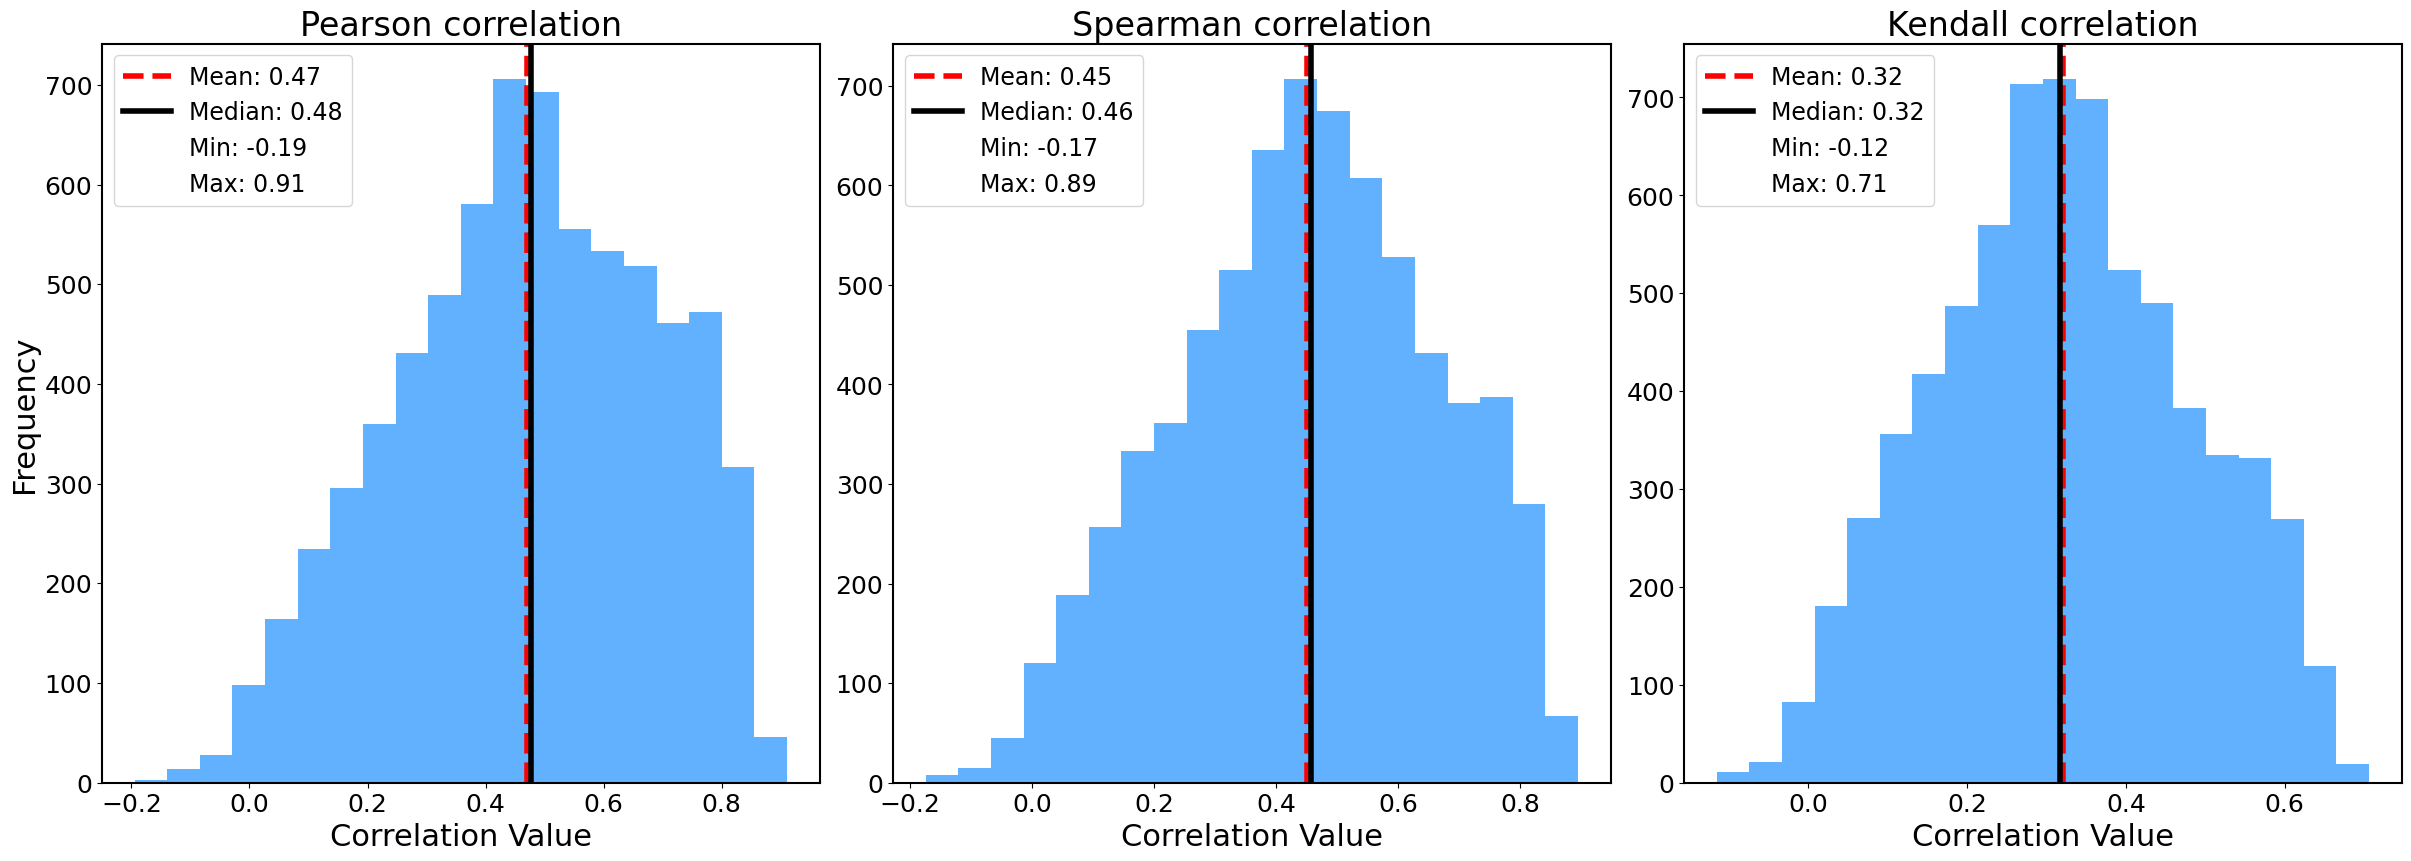

Pearson correlation - Min: -0.19, Max: 0.91
Spearman correlation - Min: -0.17, Max: 0.89
Kendall correlation - Min: -0.12, Max: 0.71


In [25]:
# Visualize distribution correlation plots

# Work only with finite values so histogram limits/statistics cannot fail because of NaNs.
corr1 = pd.Series(pearson_correlations).replace([np.inf, -np.inf], np.nan).dropna()
corr2 = pd.Series(spearman_correlations).replace([np.inf, -np.inf], np.nan).dropna()
corr3 = pd.Series(kendall_correlations).replace([np.inf, -np.inf], np.nan).dropna()

# Calculate mean, median, min, and max for each measure
mean_corr1, median_corr1 = np.mean(corr1), np.median(corr1)
mean_corr2, median_corr2 = np.mean(corr2), np.median(corr2)
mean_corr3, median_corr3 = np.mean(corr3), np.median(corr3)

min_corr1, max_corr1 = np.min(corr1), np.max(corr1)
min_corr2, max_corr2 = np.min(corr2), np.max(corr2)
min_corr3, max_corr3 = np.min(corr3), np.max(corr3)

# Set up a figure with 3 subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(24, 8.5), constrained_layout=True)

# Plot for Correlation 1
axes[0].hist(corr1, bins=20, color='dodgerblue', alpha=0.7)
axes[0].axvline(mean_corr1, color='r', linestyle='dashed', linewidth=4, label=f'Mean: {mean_corr1:.2f}')
axes[0].axvline(median_corr1, color='black', linestyle='solid', linewidth=4, label=f'Median: {median_corr1:.2f}')
axes[0].axvline(min_corr1, color='purple', linestyle='dotted', linewidth=4, label=f'Min: {min_corr1:.2f}', alpha=0)
axes[0].axvline(max_corr1, color='orange', linestyle='dotted', linewidth=4, label=f'Max: {max_corr1:.2f}', alpha=0)
axes[0].set_title('Pearson correlation')
axes[0].set_xlabel('Correlation Value')
axes[0].set_ylabel('Frequency')
axes[0].legend(loc='upper left')

# Plot for Correlation 2
axes[1].hist(corr2, bins=20, color='dodgerblue', alpha=0.7)
axes[1].axvline(mean_corr2, color='r', linestyle='dashed', linewidth=4, label=f'Mean: {mean_corr2:.2f}')
axes[1].axvline(median_corr2, color='black', linestyle='solid', linewidth=4, label=f'Median: {median_corr2:.2f}')
axes[1].axvline(min_corr2, color='purple', linestyle='dotted', linewidth=4, label=f'Min: {min_corr2:.2f}', alpha=0)
axes[1].axvline(max_corr2, color='orange', linestyle='dotted', linewidth=4, label=f'Max: {max_corr2:.2f}', alpha=0)
axes[1].set_title('Spearman correlation')
axes[1].set_xlabel('Correlation Value')
axes[1].legend(loc='upper left')

# Plot for Correlation 3
axes[2].hist(corr3, bins=20, color='dodgerblue', alpha=0.7)
axes[2].axvline(mean_corr3, color='r', linestyle='dashed', linewidth=4, label=f'Mean: {mean_corr3:.2f}')
axes[2].axvline(median_corr3, color='black', linestyle='solid', linewidth=4, label=f'Median: {median_corr3:.2f}')
axes[2].axvline(min_corr3, color='purple', linestyle='dotted', linewidth=4, label=f'Min: {min_corr3:.2f}', alpha=0)
axes[2].axvline(max_corr3, color='orange', linestyle='dotted', linewidth=4, label=f'Max: {max_corr3:.2f}', alpha=0)
axes[2].set_title('Kendall correlation')
axes[2].set_xlabel('Correlation Value')
axes[2].legend(loc='upper left')

# Adjust layout to prevent overlap

# Save as vector PDF and show
save_pdf(fig, "correlation_distributions")
plt.show()

# Print min and max values for each correlation
print(f"Pearson correlation - Min: {min_corr1:.2f}, Max: {max_corr1:.2f}")
print(f"Spearman correlation - Min: {min_corr2:.2f}, Max: {max_corr2:.2f}")
print(f"Kendall correlation - Min: {min_corr3:.2f}, Max: {max_corr3:.2f}")


In [26]:
# Check nan in Transcriptomics
# all the nan's (582) are in the same row (cell line)
transcriptomics_processed.T.isna().sum()

Unnamed: 0
LC1SQSF_LUNG                                    0
COGAR359_SOFT_TISSUE                            0
COLO794_SKIN                                    0
KKU213_BILIARY_TRACT                            0
RT4_URINARY_TRACT                               0
                                             ... 
TOLEDO_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE       0
SSP25_BILIARY_TRACT                             0
ECC2_BILIARY_TRACT                              0
A673_BONE                                       0
TT_OESOPHAGUS                                4020
Length: 1376, dtype: int64

In [27]:
# 1375 (cell lines) * 51989 (features: genes)
# The reference release has all transcriptomic NaNs in TT_OESOPHAGUS.  Do not
# assume that exact row exists in every release: identify and remove any sample
# rows that still contain NaNs.
_nan_rows = transcriptomics_processed.index[transcriptomics_processed.isna().any(axis=1)].tolist()
if _nan_rows:
    if "TT_OESOPHAGUS" in _nan_rows:
        print("Removing TT_OESOPHAGUS, the known RNA sample containing NaNs.")
    else:
        print(f"Removing {len(_nan_rows)} transcriptomic sample(s) containing NaNs: {_nan_rows[:10]}")
    transcriptomics_processed = transcriptomics_processed.drop(index=_nan_rows)
else:
    print("No transcriptomic sample rows contain NaNs; nothing to remove.")
# removed row(s) with nan's. no more nan's in RNA data.
transcriptomics_processed.shape


Removing TT_OESOPHAGUS, the known RNA sample containing NaNs.


(1375, 51989)

### Removing nan's - proteomics

In [28]:
proteomics_processed.shape

(375, 7372)

In [29]:
proteomics_processed.isna().any().sum()

2259

In [30]:
proteomics_processed = proteomics_processed.dropna(axis=1)
transcriptomics_processed = transcriptomics_processed.dropna(axis=1)

In [31]:
proteomics_processed.isna().any().sum()
transcriptomics_processed.isna().any().sum()

0

### Re-match no-nan data

In [32]:
# Extract only matched cell lines
indices = [idx for idx in proteomics_processed.index if idx in transcriptomics_processed.index]
if not indices:
    raise ValueError("No matched cell lines remain after NaN filtering.")

transcriptomics_matched = transcriptomics_processed.reindex(indices).copy()
# Check the dimensions of the two datasets
proteomics_matched = proteomics_processed.reindex(indices).copy()
transcriptomics_matched.shape, proteomics_matched.shape


((369, 51989), (369, 5113))

## Distribution Patterns

It follows cells to plot distribution patterns of the two datasets by using histograms

In [33]:
# Load filtered and matched datasets
transcriptomics = transcriptomics_matched
proteomics = proteomics_matched

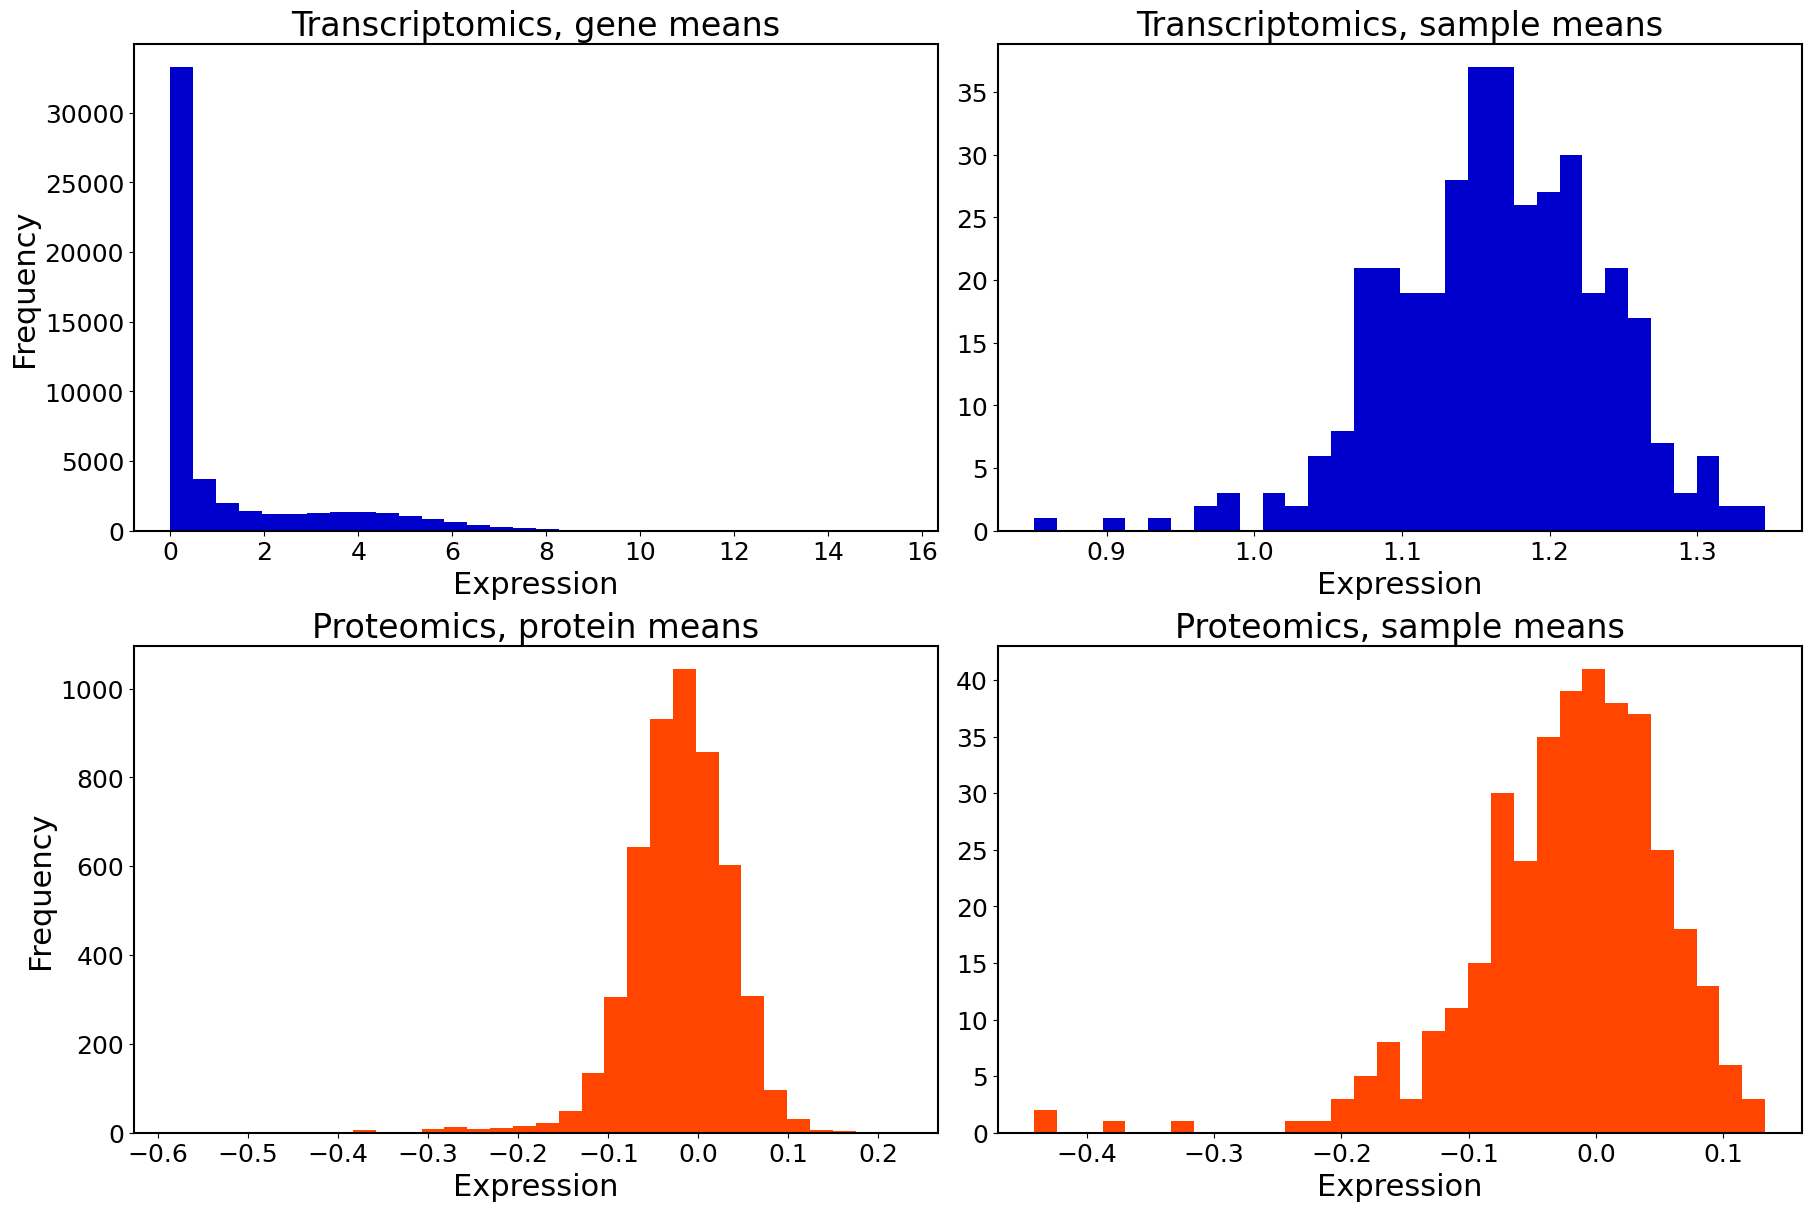

In [34]:
# Set up the subplot grid (2 rows, 2 columns)
# Define the four distributions in this same cell so it is safe to run directly
# and does not depend on a later cell having been executed first.
data1 = transcriptomics.mean(axis=0)     # gene means across samples
data2 = transcriptomics.mean(axis=1)     # sample means across genes
data3 = proteomics.mean(axis=0)          # protein means across samples
data4 = proteomics.mean(axis=1)          # sample means across proteins

fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)

# Plot histograms
data1.plot(
    kind='hist',
    bins=32,
    ax=axes[0, 0],
    color='mediumblue',
    title='Transcriptomics, gene means',
)
data2.plot(
    kind='hist',
    bins=32,
    ax=axes[0, 1],
    color='mediumblue',
    title='Transcriptomics, sample means',
)
data3.plot(
    kind='hist',
    bins=32,
    ax=axes[1, 0],
    color='orangered',
    title='Proteomics, protein means',
)
data4.plot(
    kind='hist',
    bins=32,
    ax=axes[1, 1],
    color='orangered',
    title='Proteomics, sample means',
)

# Set labels cleanly by column/row
for ax in axes.flat:
    ax.set_xlabel('Expression')

# Keep y-label only on the left column, remove from the right column
for ax in axes[:, 0]:
    ax.set_ylabel('Frequency')

for ax in axes[:, 1]:
    ax.set_ylabel('')

# Adjust layout to prevent overlap
save_pdf(fig, "ccle_transcriptomic_proteomic_distributions_titled")
plt.show()


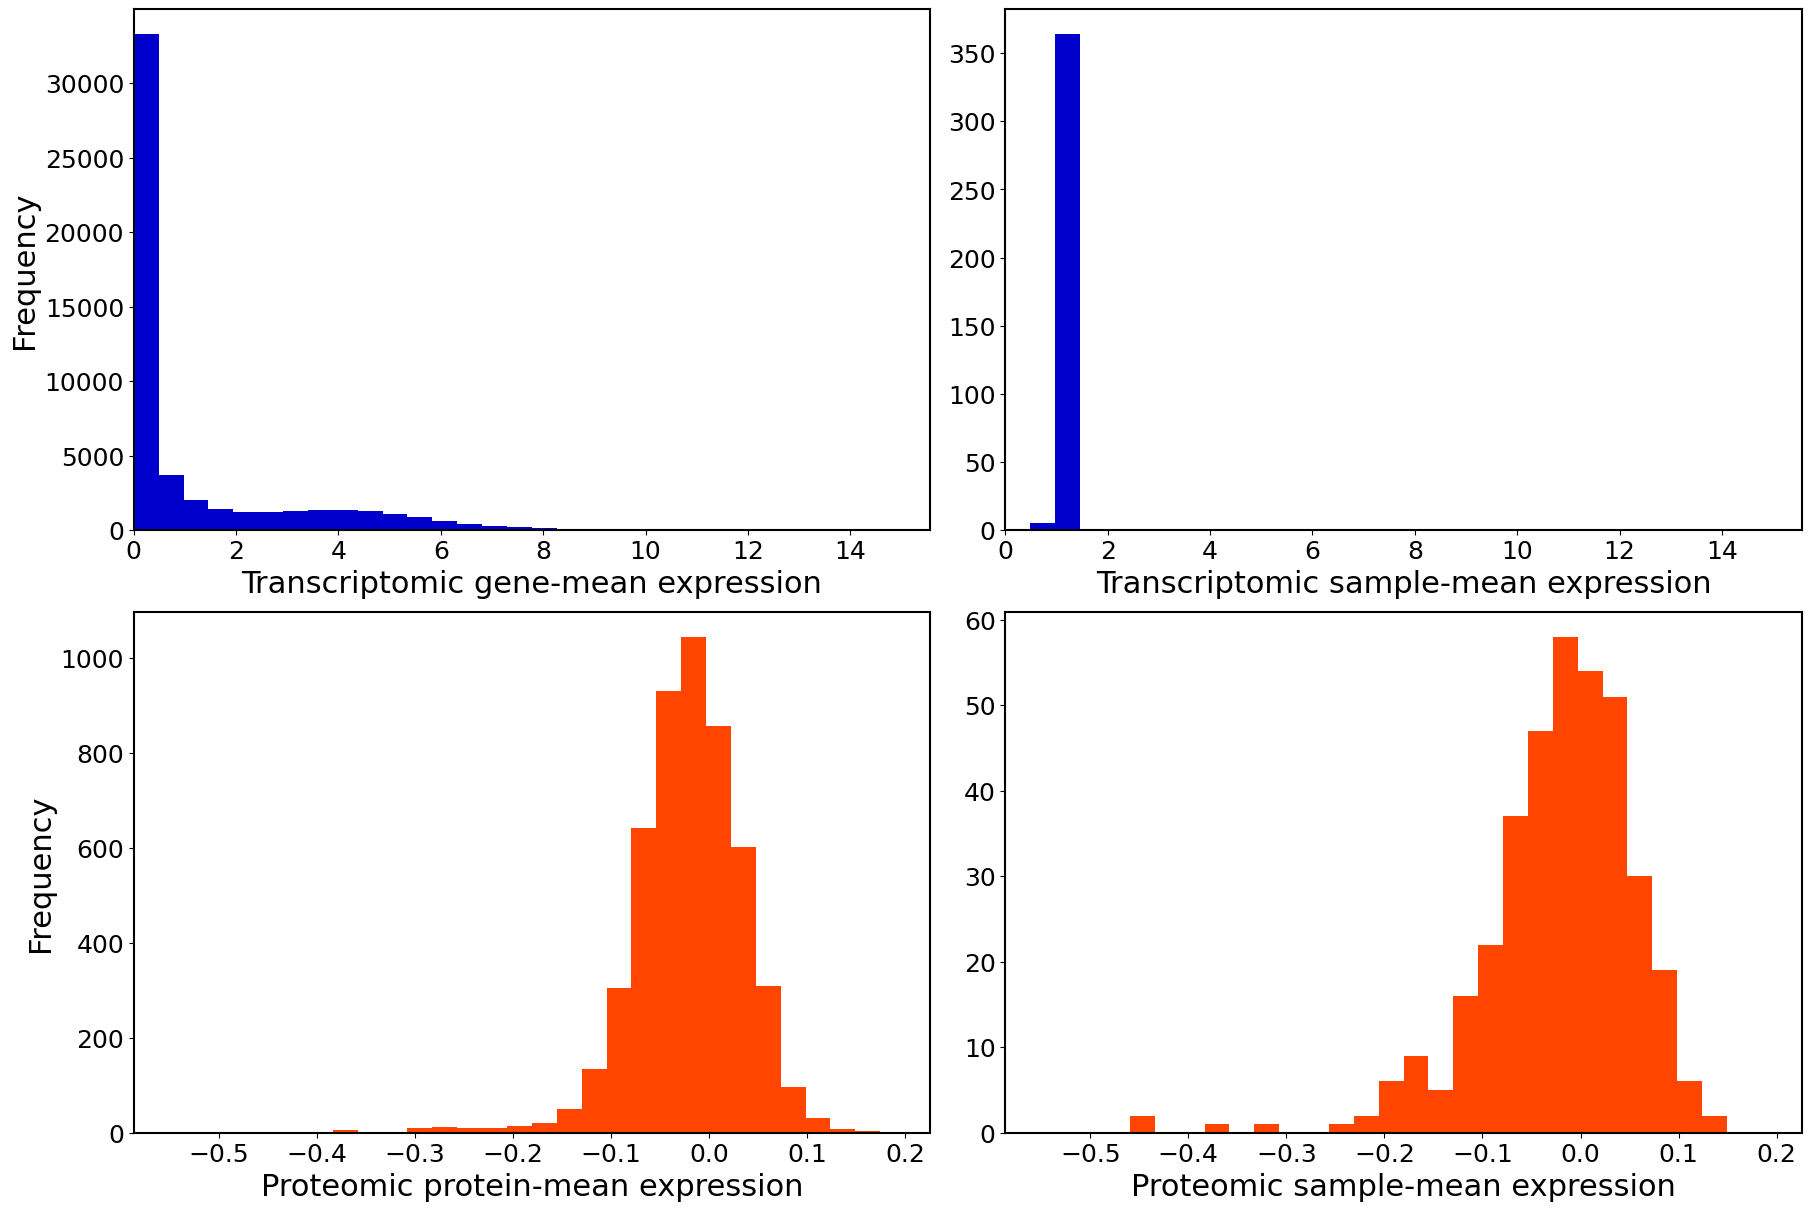

In [35]:
# Distribution plots
import numpy as np
import matplotlib.pyplot as plt

# Define these explicitly here as well, so this cell can be run independently.
data1 = transcriptomics.mean(axis=0)
data2 = transcriptomics.mean(axis=1)
data3 = proteomics.mean(axis=0)
data4 = proteomics.mean(axis=1)


def _finite_values(series):
    """Return finite numeric values as a one-dimensional array."""
    values = np.asarray(series, dtype=float).ravel()
    return values[np.isfinite(values)]


def _shared_bin_edges(*series, bins=32):
    """Create common histogram bins for all supplied series."""
    finite_blocks = [_finite_values(values) for values in series]
    finite_blocks = [values for values in finite_blocks if values.size]

    if not finite_blocks:
        return np.linspace(0.0, 1.0, bins + 1)

    pooled = np.concatenate(finite_blocks)
    lower = float(pooled.min())
    upper = float(pooled.max())

    if lower == upper:
        padding = max(abs(lower) * 0.05, 0.5)
        lower -= padding
        upper += padding

    return np.linspace(lower, upper, bins + 1)


# Identical bins and x-axis ranges within each omics layer.
transcriptomics_bins = _shared_bin_edges(data1, data2, bins=32)
proteomics_bins = _shared_bin_edges(data3, data4, bins=32)

fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)

axes[0, 0].hist(
    _finite_values(data1),
    bins=transcriptomics_bins,
    color="mediumblue",
)
axes[0, 1].hist(
    _finite_values(data2),
    bins=transcriptomics_bins,
    color="mediumblue",
)
axes[1, 0].hist(
    _finite_values(data3),
    bins=proteomics_bins,
    color="orangered",
)
axes[1, 1].hist(
    _finite_values(data4),
    bins=proteomics_bins,
    color="orangered",
)

# Enforce exactly the same x-axis range in each corresponding pair.
for ax in axes[0, :]:
    ax.set_xlim(transcriptomics_bins[0], transcriptomics_bins[-1])

for ax in axes[1, :]:
    ax.set_xlim(proteomics_bins[0], proteomics_bins[-1])

# Use axis labels instead of subplot titles.
axes[0, 0].set_xlabel("Transcriptomic gene-mean expression")
axes[0, 1].set_xlabel("Transcriptomic sample-mean expression")
axes[1, 0].set_xlabel("Proteomic protein-mean expression")
axes[1, 1].set_xlabel("Proteomic sample-mean expression")

# Keep the y-axis label only on the left-hand panels.
axes[0, 0].set_ylabel("Frequency")
axes[1, 0].set_ylabel("Frequency")
axes[0, 1].set_ylabel("")
axes[1, 1].set_ylabel("")

save_pdf(fig, "figure2_ccle_transcriptomic_proteomic_distributions")
plt.show()


In [36]:
# Cleaning and formatting index of tables
# The matched objects normally already have their samples on the index.  Keep
# compatibility with an older CSV export that may still contain "Unnamed: 0".
if "Unnamed: 0" in transcriptomics_matched.columns:
    transcriptomics_matched = transcriptomics_matched.set_index("Unnamed: 0")
if "Unnamed: 0" in proteomics_matched.columns:
    proteomics_matched = proteomics_matched.set_index("Unnamed: 0")

# Clean labels and set nice axis names
transcriptomics_matched.index = transcriptomics_matched.index.astype(str).str.strip()
transcriptomics_matched.columns = transcriptomics_matched.columns.astype(str).str.strip()
transcriptomics_matched.index.name, transcriptomics_matched.columns.name = "samples", "genes"

proteomics_matched.index = proteomics_matched.index.astype(str).str.strip()
proteomics_matched.columns = proteomics_matched.columns.astype(str).str.strip()
proteomics_matched.index.name, proteomics_matched.columns.name = "samples", "proteins"


In [37]:
# final rematch
matched_cell_lines = [line for line in transcriptomics_matched.index if line in proteomics_matched.index]
print("Final matched cell lines:", len(matched_cell_lines))
if not matched_cell_lines:
    raise ValueError("Final rematch produced zero common cell lines.")
transcriptomics_matched = transcriptomics_matched.reindex(matched_cell_lines).copy()
proteomics_matched = proteomics_matched.reindex(matched_cell_lines).copy()


Final matched cell lines: 369


In [38]:
transcriptomics_matched.isna().any().sum()


0

In [39]:
proteomics_matched.isna().any().sum()

0

In [40]:
proteomics_matched

proteins,A2M,AAAS,AACS,AAGAB,AAK1,AAMDC,AAMP,AAR2,AARS,AARS2,...,ZNF787,ZNF800,ZNF830,ZNHIT6,ZNRD1,ZRANB2,ZW10,ZWILCH,ZYX,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,-0.345562,-0.109405,0.370945,0.009639,0.005800,1.588762,-0.364119,-0.031192,-0.052310,-0.282176,...,-0.094039,-0.273452,-0.222986,0.110619,-0.220072,0.320284,-0.109837,-0.234132,-1.032888,-0.054057
SH4_SKIN,1.642186,-0.283335,0.162102,-0.057517,0.760639,0.119699,0.105279,-0.075316,0.399385,1.102265,...,-0.248390,0.531159,-0.452978,-0.386262,-0.047313,-0.499179,-0.208351,-0.163901,-0.361225,-0.371537
AU565_BREAST,-1.129114,0.024663,1.071283,-0.758048,-0.320451,-1.068118,-0.158266,0.365150,-0.797109,-0.272314,...,0.043493,1.607322,-0.547892,-0.175286,0.061356,-0.175592,0.071945,-0.393799,0.309026,-0.301741
KMRC1_KIDNEY,1.493333,-0.588886,0.404605,-0.210457,0.533949,0.437453,-0.070486,-0.045454,0.048472,-0.352636,...,-0.226766,-0.363713,0.001180,-0.517588,-0.286447,-0.326172,0.019450,-0.055173,0.574568,-0.732279
CAL51_BREAST,0.274652,0.673324,-0.587890,-0.044001,-0.778679,0.051707,0.294878,-0.211209,-0.436950,0.113565,...,0.319720,-0.184053,0.322673,-0.294126,0.161771,-0.060968,0.103745,0.151656,-0.218916,0.697868
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,-1.116991,-0.779655,-0.343373,0.032533,-1.433436,-0.991085,-0.899321,-0.620034,-0.625103,-0.697012,...,0.821462,0.343556,0.993749,-0.348426,1.067482,0.125648,-0.894195,-0.610845,-0.306374,-0.005547
KP4_PANCREAS,1.922976,-0.628770,-1.200965,2.101721,-0.549493,1.602728,0.949461,-0.512347,-0.856384,-0.896097,...,-0.473678,-0.024037,1.098143,0.337931,1.372841,-0.052092,-0.519440,-0.873276,1.281937,1.008579
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-1.106344,1.205109,0.660346,-0.539838,0.951283,0.139173,-0.211486,0.418099,-0.894781,0.713249,...,0.271313,0.084621,0.244403,0.347557,0.136414,0.282679,0.672338,0.885732,-0.498927,-0.157715


In [41]:
transcriptomics_matched

genes,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A2ML1-AS2,A2MP1,A3GALT2,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.275007,0.443607,0.0,0.0,0.000000,0.056584,...,6.986752,2.192194,3.114367,4.250962,2.792855,0.000000,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.887525,0.000000,0.0,0.0,0.028569,0.000000,...,6.113742,1.384050,2.659925,4.979111,0.014355,1.084064,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,0.454176,2.451541,0.0,0.0,0.000000,0.028569,...,7.373909,0.632268,2.049631,3.471187,0.014355,0.000000,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,0.000000,0.0,0.0,0.000000,0.000000,...,6.704734,0.432959,1.021480,1.475085,0.485427,0.000000,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.201634,0.713696,0.0,0.0,0.000000,0.000000,...,7.356496,1.700440,2.424922,3.884598,0.084064,0.000000,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.464668,0.263034,0.0,0.0,0.000000,0.000000,...,7.543882,0.014355,0.028569,3.807355,0.790772,0.000000,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.250962,0.150560,0.0,0.0,0.000000,0.056584,...,6.656067,2.137504,2.558268,3.754888,0.042644,0.000000,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.454176,0.070389,0.0,0.0,0.000000,0.000000,...,7.929318,1.137504,1.835924,4.955127,0.056584,0.000000,2.107688,5.816856,3.693766,5.030777


In [42]:
# Save datasets
data_dir.mkdir(parents=True, exist_ok=True)
dump(transcriptomics_matched, data_dir / "transcriptomics_matched.joblib")
dump(proteomics_matched, data_dir / "proteomics_matched.joblib")
print("Saved:", data_dir / "transcriptomics_matched.joblib")
print("Saved:", data_dir / "proteomics_matched.joblib")


Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\01. pre-processing\data\transcriptomics_matched.joblib
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\01. pre-processing\data\proteomics_matched.joblib
